# N02: VLM descriptions

The baseline fails on what the metadata does not say. Here a vision-language model (`qwen/qwen3-vl-8b-instruct` via
OpenRouter, temperature 0) writes 2 sentences about each painting, once, offline. At query time only the visitor's
question is encoded, so the kiosk does not need the VLM.

- R2 searches the description only (one change from R1: metadata -> visual text).
- R3 searches description + metadata.

Cost: about 1,080 images (dev + test; train is not used) at about 64 image tokens each, roughly $0.10-0.30.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from deep_learning_project_waerniers_lamy_mahieddine.nlp import utils as u

c:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Generate the descriptions (once)

Needs an OpenRouter key in the environment (`$env:OPENROUTER_API_KEY = "sk-or-..."` in PowerShell before starting
Jupyter). Resumable: already described paintings are skipped. Try `limit=5` first and read them.

In [2]:
assert os.environ.get("OPENROUTER_API_KEY"), "set OPENROUTER_API_KEY first"
descriptions = u.generate_descriptions(limit=5)

5 descriptions in C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\results\nlp\paintings_described.csv, 0 failed


In [3]:
descriptions = u.generate_descriptions()  # all remaining dev + test paintings

100/1075
200/1075
300/1075
400/1075
500/1075
600/1075
700/1075
800/1075
900/1075
1000/1075
1080 descriptions in C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\results\nlp\paintings_described.csv, 0 failed


## 2. Look at a few

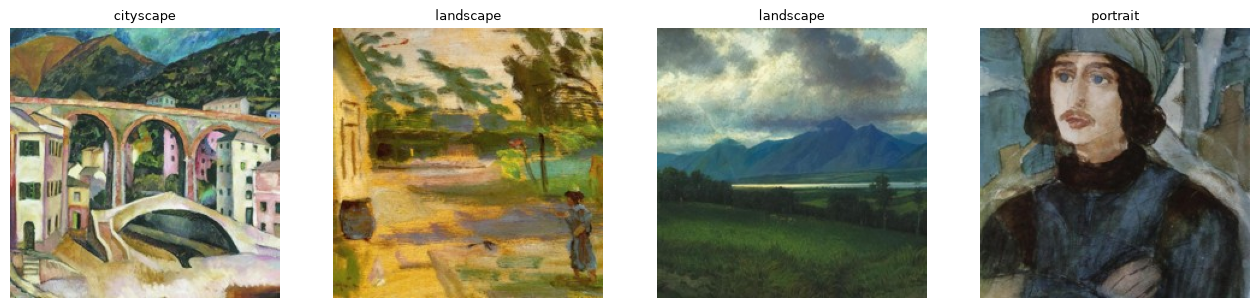

s51_r0131: A vibrant village clings to hillsides beneath a stone aqueduct, nestled beside a river. Warm, luminous hues and soft light evoke a sun-drenched, tranquil Mediterranean atmosphere.
s51_r0981: A solitary figure walks a sun-dappled rural path beside a rustic building, with trees and distant hills framing the scene. Warm yellows and greens glow under dappled light, evoking a peaceful, golden-hour atmosphere.
s51_r1066: A serene valley stretches beneath dramatic, cloud-filled skies, framed by distant mountains and a calm lake. Rich greens and cool blues evoke tranquility, while soft, diffused light enhances the misty, contemplative atmosphere.
s58_r0414: A solemn young man in a dark tunic and head covering gazes thoughtfully. Cool blues and muted earth tones create a quiet, introspective atmosphere, with soft light highlighting his face against a blurred, natural backdrop.


In [4]:
paintings = u.load_corpus("dev")
descriptions = u.load_descriptions()
sample = paintings.sample(4, random_state=u.SEED)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (_, row) in zip(axes, sample.iterrows()):
    ax.imshow(Image.open(u.DATA_DIR / row["path"]))
    ax.set_title(row["genre"], fontsize=9)
    ax.axis("off")
plt.show()
for _, row in sample.iterrows():
    print(f"{row['id']}: {descriptions[row['id']]}")

Two checks on the descriptions:
- length: the prompt asks for 2 short sentences, at most 45 words (ADR 0005); every description should end with a full stop (none cut off);
- **artist leak**: if the VLM recognises famous works and names the artist, R2 would partly be using metadata, not
  only what it sees.

In [5]:
words = pd.Series([len(descriptions[i].split()) for i in paintings["id"]])
print("words per description:", words.describe().round(1).to_dict())
cut = [i for i in paintings["id"] if not descriptions[i].rstrip().endswith((".", "!", "?"))]
print(f"cut off mid-sentence: {len(cut)} of {len(paintings)}", cut[:5])
print("artist named in the description:", round(u.artist_leak_rate(paintings, descriptions), 3))

words per description: {'count': 480.0, 'mean': 31.8, 'std': 3.3, 'min': 21.0, '25%': 30.0, '50%': 32.0, '75%': 34.0, 'max': 42.0}
cut off mid-sentence: 0 of 480 []
artist named in the description: 0.0


## 3. Rank, grade the new top-5 paintings

In [6]:
queries = u.QUERIES["text"].tolist()
scores = {
    "R0 random": u.rung_random(paintings, queries),
    "R1 metadata": u.rung_metadata(paintings, queries),
    "R2 description": u.rung_description(paintings, queries, descriptions),
    "R3 description+metadata": u.rung_description_metadata(paintings, queries, descriptions),
}
u.judge_with_llm("dev", scores, paintings)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 16913.18it/s]


247 new (query, painting) pairs to grade with google/gemini-3.8-flash
100/247
200/247
644 judgments in C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\results\nlp\qrels_dev.json, 0 failed


{'q01': {'s42_r0523': 0,
  's49_r0203': 0,
  's51_r0277': 0,
  's51_r0672': 0,
  's51_r0941': 0,
  's51_r0947': 0,
  's51_r1050': 0,
  's54_r0082': 0,
  's58_r0276': 0,
  's58_r0692': 0,
  's54_r0424': 2,
  's54_r0375': 2,
  's54_r0450': 2,
  's54_r0593': 2,
  's54_r0618': 2,
  's54_r0714': 0},
 'q02': {'s42_r0640': 0,
  's49_r0183': 0,
  's49_r0261': 0,
  's49_r0303': 0,
  's49_r0317': 0,
  's49_r0533': 0,
  's49_r0642': 0,
  's51_r0444': 0,
  's58_r0296': 0,
  's58_r0604': 0,
  's54_r0659': 1,
  's54_r0672': 2,
  's54_r0346': 2,
  's54_r0677': 2,
  's54_r0451': 1,
  's54_r0274': 1,
  's54_r0763': 1,
  's54_r0567': 2},
 'q03': {'s49_r0454': 2,
  's49_r1014': 1,
  's54_r0278': 0,
  's54_r0333': 0,
  's54_r0346': 0,
  's54_r0375': 0,
  's54_r0460': 0,
  's54_r0496': 0,
  's54_r0550': 0,
  's54_r0726': 0,
  's58_r0183': 1,
  's42_r0268': 1,
  's58_r0354': 2,
  's42_r0695': 2,
  's58_r0135': 1},
 'q04': {'s42_r0079': 2,
  's42_r0341': 0,
  's42_r0473': 0,
  's51_r0124': 0,
  's51_r0249': 

### Judging

Every painting in the new top 5 of a rung is graded by an LLM judge (`u.JUDGE_MODEL`, another model family than the
description generator). It sees **only the query and the image**, answers two yes/no questions (is the main subject
there? does it match the whole query?) and the grade follows by rule: 0, 1 or 2. Grades are saved in
`results/nlp/qrels_dev.json`; already graded pairs are never sent again. The judge is validated against 150 of your own
grades in N04 before any result is frozen.

## 4. Results

Earlier rungs are re-scored with all judgments so far: the ideal ranking of a query can only improve as more relevant
paintings are found, so their nDCG may move slightly. The question of this step: **does visual text beat metadata?**
(R2 vs R1, paired over the same queries; pre-registered comparison 1 of 3.)

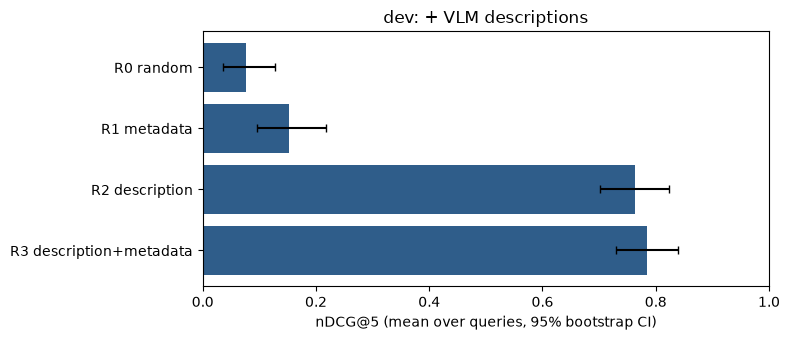

,rung,queries,nDCG@5,nDCG low,nDCG high,Success@5,Success low,Success high,judged@5
0,R0 random,39,0.076,0.035,0.127,0.128,0.026,0.231,1.0
1,R1 metadata,39,0.153,0.096,0.217,0.256,0.128,0.385,1.0
2,R2 description,39,0.763,0.702,0.823,0.923,0.821,1.000,1.0
3,R3 description+metadata,39,0.785,0.729,0.840,0.923,0.821,1.000,1.0


,system,reference,delta nDCG@5,p,p (Holm)
0,R2 description,R1 metadata,0.6104,0.0001,0.0001


In [7]:
per_query = u.per_query_scores("dev", scores, paintings)
table = u.summary_table(per_query)
u.plot_ladder(table, "dev: + VLM descriptions")
display(table)
u.compare(per_query, [("R2 description", "R1 metadata")])

In [8]:
per_query.groupby(["rung", "category"])["ndcg@5"].mean().unstack().round(3)

category,compound,mood_colour,object,scene
rung,,,,
R0 random,0.015,0.236,0.043,0.022
R1 metadata,0.175,0.310,0.095,0.055
R2 description,0.659,0.740,0.891,0.738
R3 description+metadata,0.712,0.774,0.858,0.780
